# Direct-panel tone test: measured vs. additive prediction

**Primary question:** Does the microphone recording with **both** speakers active equal the sum of the recordings with each speaker active separately?

For a linear additive system, $e_{both}(t)=e_{panel}(t)+e_{source}(t)$ **provided all three recordings share a common time/phase reference**. Independent recordings generally do **not**: phase shifts can make a raw waveform subtraction misleading even for a perfectly linear system.

This notebook therefore uses a **phase-insensitive, power-spectrum comparison** as the default. At frequencies where the two sources contribute distinct, non-overlapping tones, predicted power is the sum of the individual powers. At frequencies where both sources contribute coherently (harmonic overlap), this is **not** an exact prediction. A separate optional waveform comparison is provided **only if your acquisition is synchronized across takes**.

First number in each key = panel frequency; second = source frequency. No adaptation is assumed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from pathlib import Path

PATH = Path('./data/direct_close.npz')
FS = 96_000
TRIM_START_S = 0  # remove turn-on transient; change to suit recordings
TRIM_END_S = 0
N_PER_SEG = 16384   # Welch frequency resolution ~5.86 Hz at 96 kHz
BAND_HZ = 12.0      # integrated power around each expected line
PLOT_MAX_HZ = 2500
PAIRS = [(p, s) for p in (300, 500) for s in (700, 1000, 1500)]

with np.load(PATH) as data:
    recordings = {key: np.asarray(data[key], dtype=np.float64).ravel().copy() for key in data.files}

for p, s in PAIRS:
    for key in (f'e_{p}_0', f'e_0_{s}', f'e_{p}_{s}'):
        if key not in recordings:
            raise KeyError(f'Missing {key} in {PATH}')
print('Loaded', len(recordings), 'recordings')
print({k: round(len(v)/FS, 3) for k,v in recordings.items()})

Loaded 11 recordings
{'e_0_700': 1.0, 'e_0_1000': 1.0, 'e_0_1500': 1.0, 'e_300_0': 1.0, 'e_500_0': 1.0, 'e_300_700': 1.0, 'e_300_1000': 1.0, 'e_300_1500': 1.0, 'e_500_700': 1.0, 'e_500_1000': 1.0, 'e_500_1500': 1.0}


## 1. Preprocessing and power-spectrum estimate

Each take is trimmed **independently**. The Welch PSD is in power/Hz. Comparing power (not adding dB values or magnitude spectra) avoids arbitrary start-phase differences for non-overlapping spectral components.

A warning: if there are large changes in gain, mic placement, timing drift, or speaker behavior between takes, those differences also appear as departures from additivity.

In [2]:
def trim(x):
    left = int(round(TRIM_START_S * FS))
    right = int(round(TRIM_END_S * FS))
    stop = len(x) - right if right else len(x)
    if stop - left < 128:
        raise ValueError('Recording too short for requested trim')
    return signal.detrend(x[left:stop], type='constant')

def welch_psd(x):
    seg = min(N_PER_SEG, len(x))
    return signal.welch(x, fs=FS, window='hann', nperseg=seg,
                        noverlap=seg//2, scaling='density')

def db(x):
    return 10*np.log10(np.maximum(x, 1e-30))

def spectra(p, s):
    a, b, both = [trim(recordings[k]) for k in
                  (f'e_{p}_0', f'e_0_{s}', f'e_{p}_{s}')]
    f, Pa = welch_psd(a)
    fb, Pb = welch_psd(b)
    fc, Pboth = welch_psd(both)
    if not (np.array_equal(f, fb) and np.array_equal(f, fc)):
        raise ValueError('Welch grids differ: recordings too short or inconsistent')
    return f, Pa, Pb, Pboth

for p,s in PAIRS:
    f, Pa, Pb, Pboth = spectra(p,s)
    print(f'{p} + {s} Hz: {len(f)} PSD bins; bin width {f[1]-f[0]:.2f} Hz')

300 + 700 Hz: 8193 PSD bins; bin width 5.86 Hz
300 + 1000 Hz: 8193 PSD bins; bin width 5.86 Hz
300 + 1500 Hz: 8193 PSD bins; bin width 5.86 Hz
500 + 700 Hz: 8193 PSD bins; bin width 5.86 Hz
500 + 1000 Hz: 8193 PSD bins; bin width 5.86 Hz
500 + 1500 Hz: 8193 PSD bins; bin width 5.86 Hz


## 2. Main comparison: measured both-on vs. predicted sum

**Solid:** measured both-on PSD. **Dashed:** panel-only PSD + source-only PSD. **Bottom:** ratio in dB. The ratio is only directly interpretable at frequencies where phase-coherent overlap is negligible. Noise floors also add in the predicted PSD, so broadband residual differences can reflect noise statistics.

In particular, a mismatch at a shared harmonic is *not automatically distortion*: unknown relative phase creates interference.

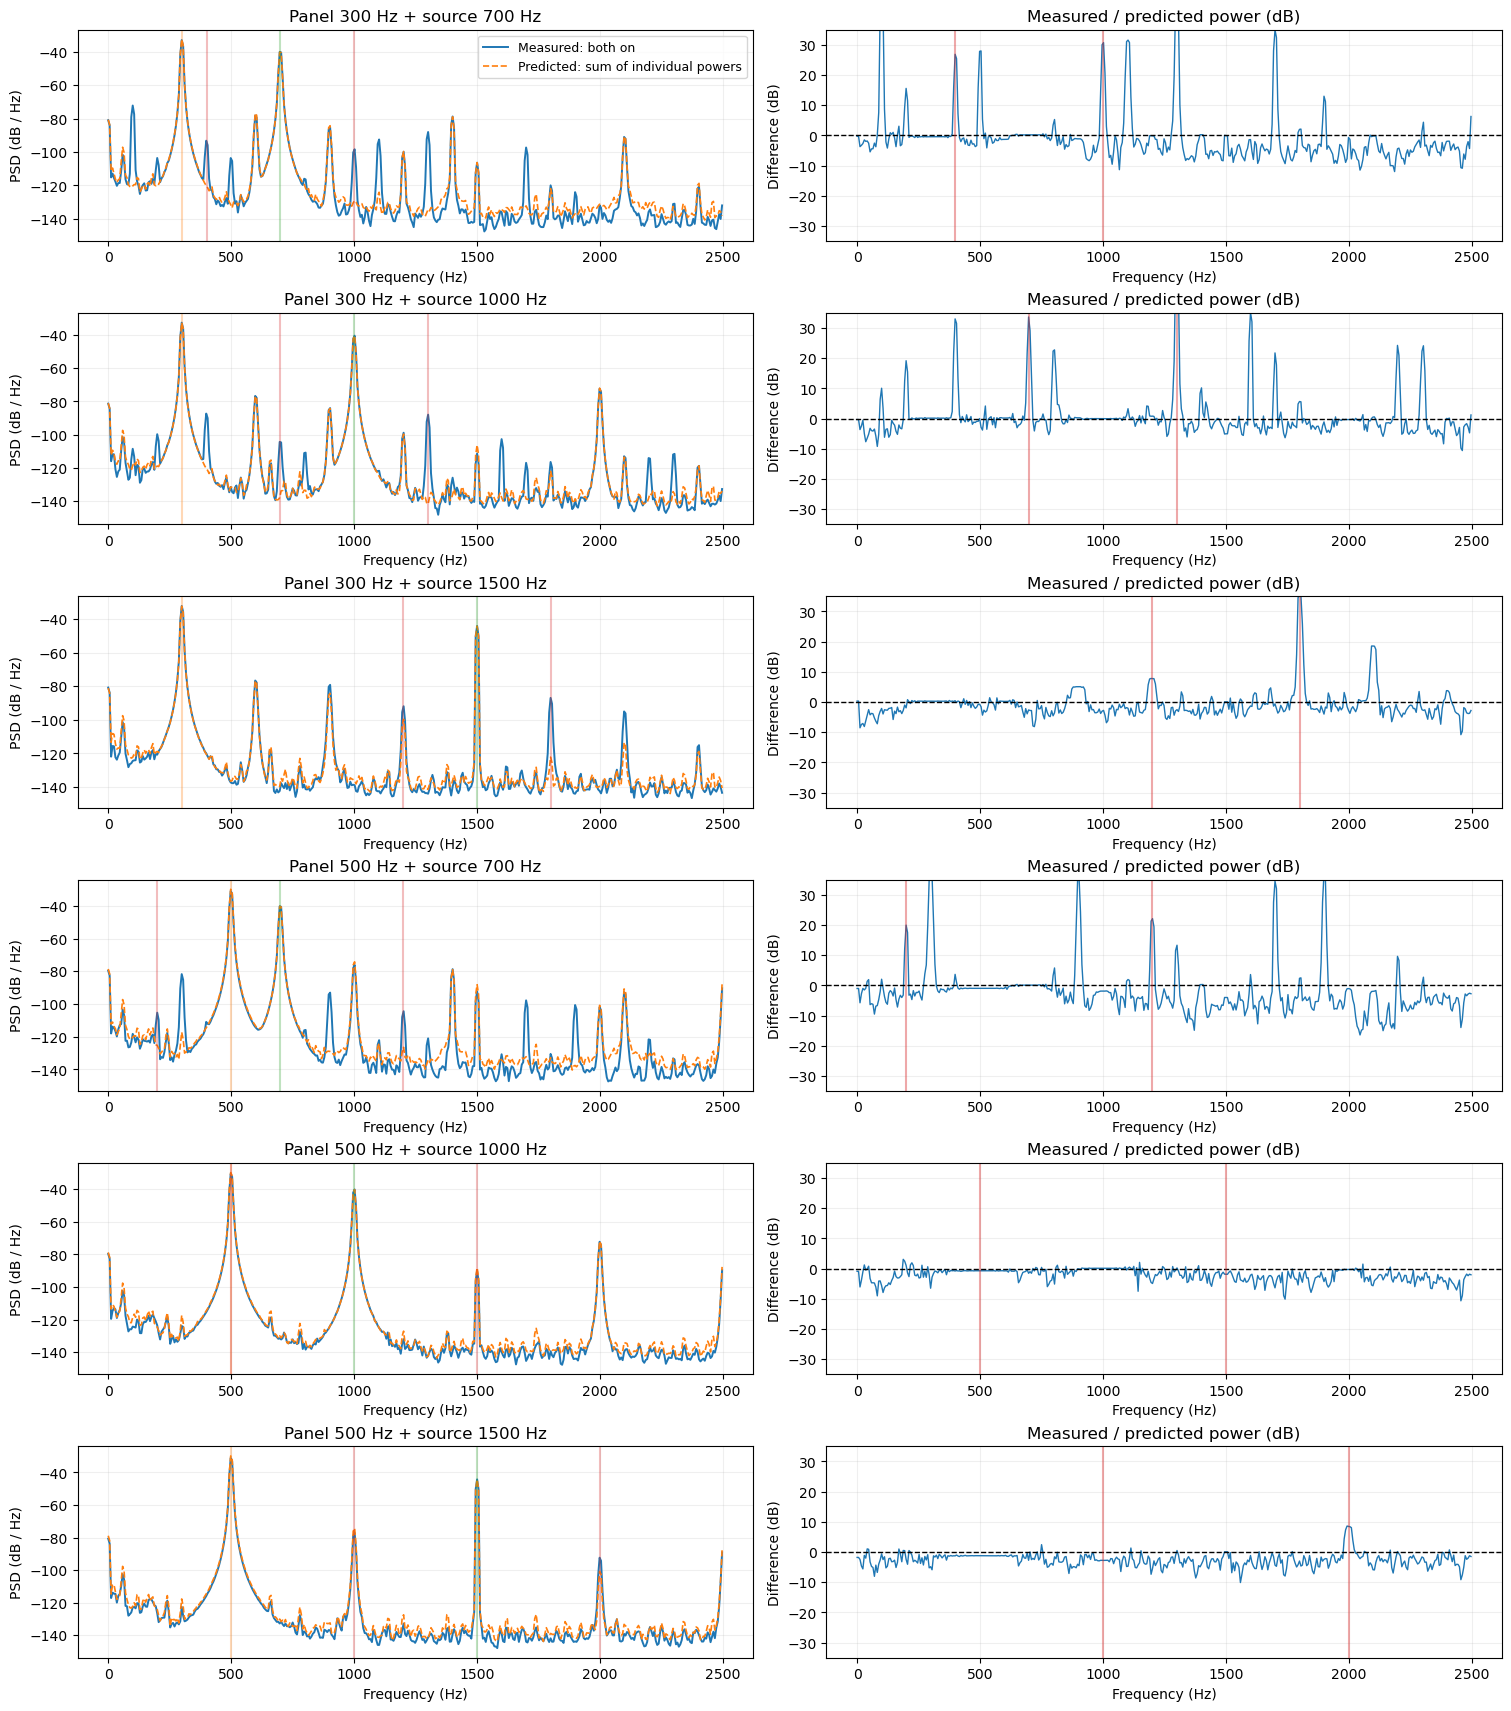

In [3]:
fig, axes = plt.subplots(len(PAIRS), 2, figsize=(15, 17), constrained_layout=True)
for row, (p,s) in enumerate(PAIRS):
    f, Pa, Pb, Pboth = spectra(p,s)
    Ppred = Pa + Pb
    mask = (f <= PLOT_MAX_HZ)
    ax, axr = axes[row]
    ax.plot(f[mask], db(Pboth[mask]), label='Measured: both on', lw=1.4)
    ax.plot(f[mask], db(Ppred[mask]), '--', label='Predicted: sum of individual powers', lw=1.2)
    for line, color in [(p, 'tab:orange'), (s, 'tab:green'), (abs(s-p), 'tab:red'), (s+p, 'tab:red')]:
        ax.axvline(line, alpha=0.3, color=color)
    ax.set(title=f'Panel {p} Hz + source {s} Hz', xlabel='Frequency (Hz)', ylabel='PSD (dB / Hz)')
    ax.grid(alpha=.2)
    axr.plot(f[mask], db(Pboth[mask]) - db(Ppred[mask]), lw=1)
    axr.axhline(0, color='black', ls='--', lw=1)
    for line in (abs(s-p), s+p):
        axr.axvline(line, color='tab:red', alpha=.4)
    axr.set(title='Measured / predicted power (dB)', xlabel='Frequency (Hz)', ylabel='Difference (dB)', ylim=(-35,35))
    axr.grid(alpha=.2)
axes[0,0].legend(fontsize=9)
plt.show()

## 3. Quantify sidebands and check harmonic overlaps

Integrate PSD in a small band around each $f_s\pm f_p$ and compare measured vs. the sum of the individual powers. Report both the difference (dB) and excess power $P_{both}-P_{pred}$; excess power may be negative from phase interference or run-to-run variation.

**Overlap flag:** whether a sideband coincides with an integer harmonic of either excitation. Such bins are ambiguous without phase-synchronized measurements. In these tests, 500+1000 Hz and 500+1500 Hz have important overlaps.

In [4]:
def band_power(f, P, center, half_width=BAND_HZ):
    mask = np.abs(f-center) <= half_width
    if not mask.any():
        raise ValueError('Band narrower than FFT bin spacing')
    return np.sum(P[mask]) * (f[1]-f[0])

def harmonic_overlap(target, p, s, tolerance=BAND_HZ):
    matches=[]
    for base, name in ((p,'panel'),(s,'source')):
        for order in range(1, 1+int(PLOT_MAX_HZ/base)):
            if abs(target-order*base) <= tolerance:
                matches.append(f'{name} harmonic {order}')
    return ', '.join(matches)

rows=[]
for p,s in PAIRS:
    f, Pa, Pb, Pboth = spectra(p,s)
    for label, target in (('lower',abs(s-p)),('upper',s+p)):
        observed = band_power(f,Pboth,target)
        predicted = band_power(f,Pa+Pb,target)
        rows.append(dict(panel_Hz=p, source_Hz=s, sideband=label, frequency_Hz=target,
                         measured_dB=db(observed), predicted_dB=db(predicted),
                         difference_dB=db(observed)-db(predicted),
                         excess_power=observed-predicted,
                         harmonic_overlap=harmonic_overlap(target,p,s)))
summary = pd.DataFrame(rows)
display(summary.round(2))

,panel_Hz,source_Hz,sideband,frequency_Hz,measured_dB,predicted_dB,difference_dB,excess_power,harmonic_overlap
0,300,700,lower,400,-83.38,-106.84,23.46,0.0,
1,300,700,upper,1000,-88.31,-116.58,28.27,0.0,
2,300,1000,lower,700,-93.67,-121.88,28.21,0.0,
3,300,1000,upper,1300,-78.40,-125.56,47.16,0.0,
4,300,1500,lower,1200,-82.27,-90.04,7.77,0.0,panel harmonic 4
5,300,1500,upper,1800,-77.30,-112.39,35.08,0.0,panel harmonic 6
6,500,700,lower,200,-95.75,-112.79,17.04,0.0,
7,500,700,upper,1200,-94.78,-116.01,21.23,0.0,
8,500,1000,lower,500,-20.48,-19.78,-0.69,-0.0,panel harmonic 1
9,500,1000,upper,1500,-80.63,-78.79,-1.84,-0.0,panel harmonic 3


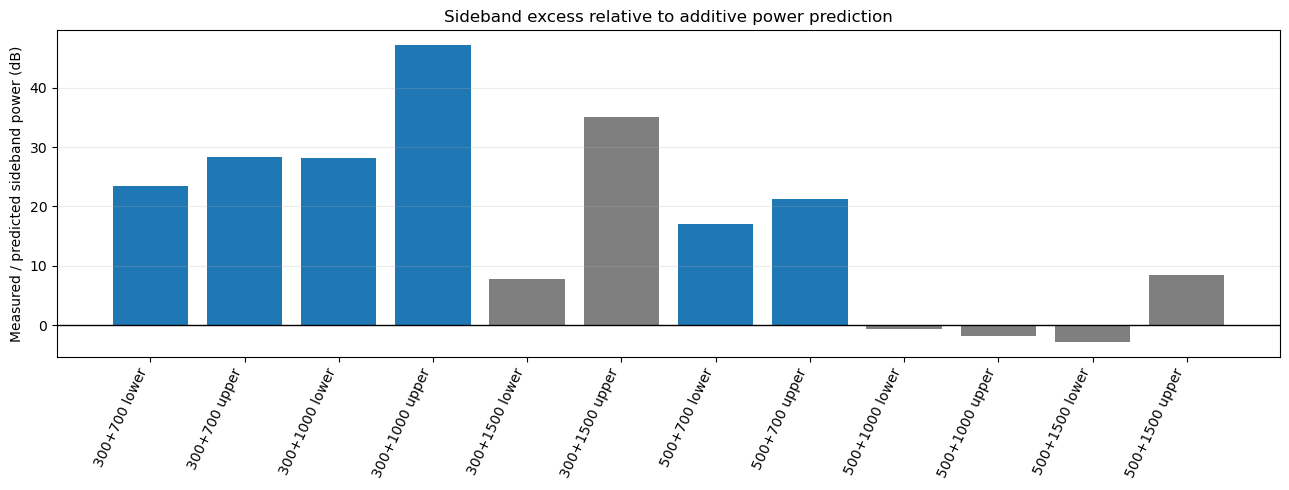

Gray = overlaps a harmonic of one of the driving tones; interpret cautiously.


In [5]:
fig,ax=plt.subplots(figsize=(13,5))
labels=[f"{r.panel_Hz}+{r.source_Hz} {r.sideband}" for r in summary.itertuples()]
colors=['tab:gray' if r.harmonic_overlap else 'tab:blue' for r in summary.itertuples()]
ax.bar(np.arange(len(summary)),summary.difference_dB,color=colors)
ax.axhline(0,color='black',lw=1)
ax.set_xticks(np.arange(len(labels)),labels,rotation=65,ha='right')
ax.set(ylabel='Measured / predicted sideband power (dB)',title='Sideband excess relative to additive power prediction')
ax.grid(axis='y',alpha=.25)
plt.tight_layout();plt.show()
print('Gray = overlaps a harmonic of one of the driving tones; interpret cautiously.')

## 4. Time-frequency comparison

Welch averages over time. Here we compare the **measured both-on spectrogram** to the **sum of the two individual spectrogram powers**. The three recordings do not need to be phase-aligned for this comparison at isolated spectral lines, but their time axes must represent similar stages of each test. The difference is not a coherent waveform residual.

Choose a pair below; adjust `STFT_NPERSEG` to trade frequency resolution against temporal resolution.

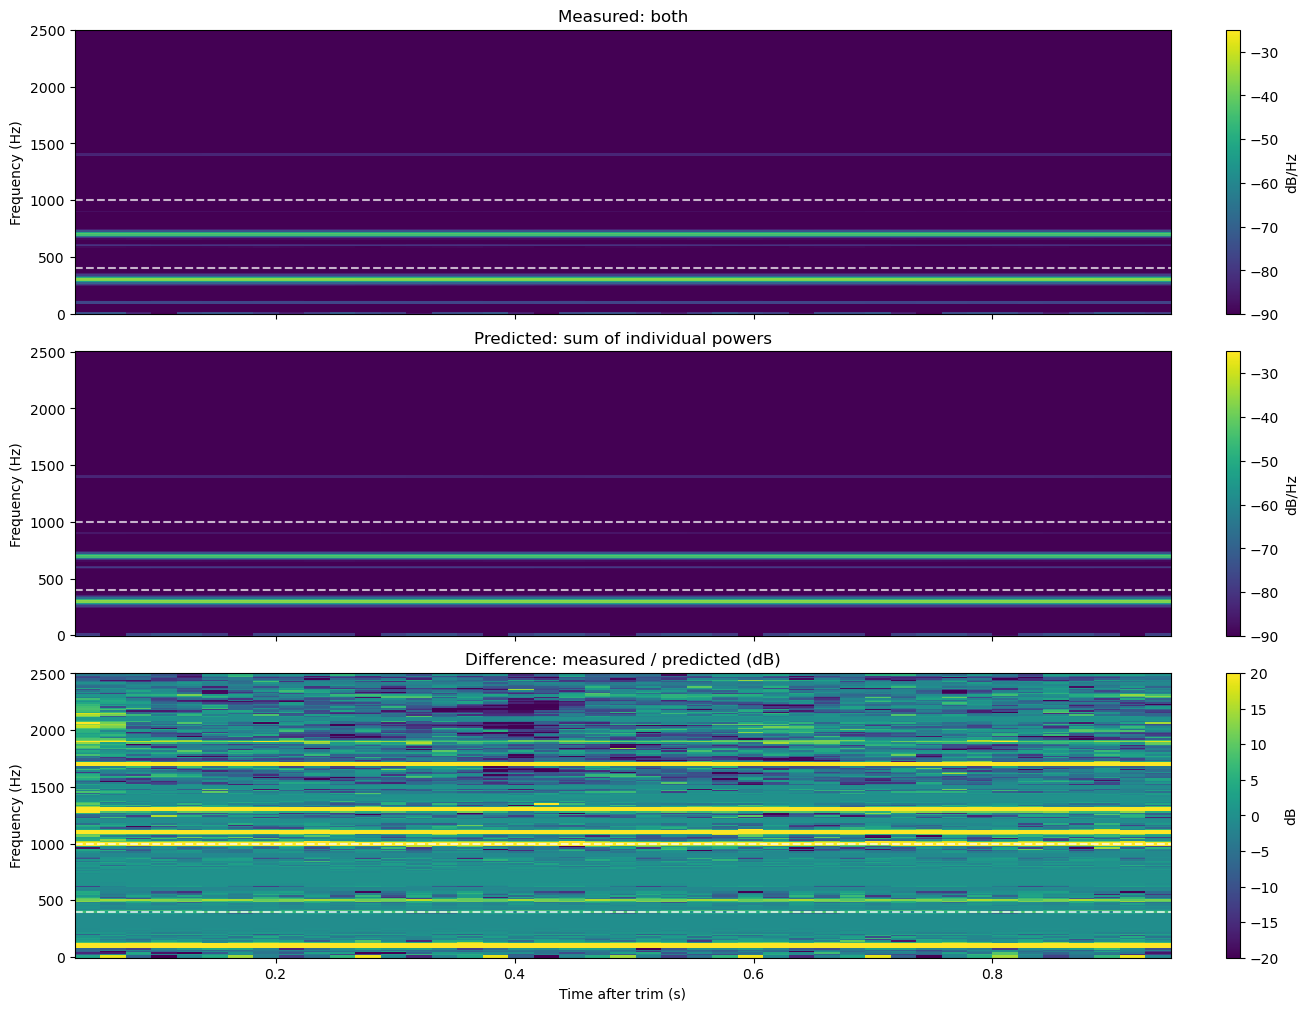

In [6]:
SELECT_PANEL, SELECT_SOURCE = 300, 700
STFT_NPERSEG = 8192

def spectrogram_psd(x):
    return signal.spectrogram(x, fs=FS, window='hann', nperseg=STFT_NPERSEG,
                              noverlap=STFT_NPERSEG*3//4, scaling='density', mode='psd')

p,s=SELECT_PANEL,SELECT_SOURCE
x1,x2,xb=[trim(recordings[k]) for k in (f'e_{p}_0',f'e_0_{s}',f'e_{p}_{s}')]
f1,t1,S1=spectrogram_psd(x1)
f2,t2,S2=spectrogram_psd(x2)
f3,t3,Sb=spectrogram_psd(xb)
nt=min(S1.shape[1],S2.shape[1],Sb.shape[1])
Sp=S1[:,:nt]+S2[:,:nt]
Sb=Sb[:,:nt]
mask=f3<=PLOT_MAX_HZ
fig,axes=plt.subplots(3,1,figsize=(13,10),sharex=True,sharey=True,constrained_layout=True)
for ax, data, name in zip(axes,[db(Sb),db(Sp),db(Sb)-db(Sp)],
                         ['Measured: both','Predicted: sum of individual powers','Difference: measured / predicted (dB)']):
    im=ax.pcolormesh(t3[:nt],f3[mask],data[mask],shading='auto',cmap='viridis',
                     vmin=(-90 if 'Difference' not in name else -20),
                     vmax=(-25 if 'Difference' not in name else 20))
    for target in (abs(s-p),s+p): ax.axhline(target,color='white',ls='--',alpha=.7)
    ax.set(ylabel='Frequency (Hz)',title=name)
    fig.colorbar(im,ax=ax,label='dB/Hz' if 'Difference' not in name else 'dB')
axes[-1].set_xlabel('Time after trim (s)')
plt.show()

## 5. Optional: actual waveform addition and coherent residual (synchronized recordings only)

**Do not interpret this section unless** each recording has a shared sample-clock/trigger reference and the acoustic/electronic phase is reproducible across takes. Arbitrarily cross-correlating the tones to force a match can hide the very interaction you're testing. If your captures were started independently, leave `SYNCHRONIZED_TAKES = False`.

With synchronized takes, plot the actual waveform against the samplewise sum and compute the residual. This is the strongest linearity test, but requires reproducible timing and phase. Ideally also record an all-off baseline and use $e_{both}-e_{panel}-e_{source}+e_{off}$ to remove fixed offsets/background.

In [7]:
SYNCHRONIZED_TAKES = False
if SYNCHRONIZED_TAKES:
    p,s=SELECT_PANEL,SELECT_SOURCE
    a,b,c=[trim(recordings[k]) for k in (f'e_{p}_0',f'e_0_{s}',f'e_{p}_{s}')]
    n=min(len(a),len(b),len(c))
    predicted=a[:n]+b[:n]
    residual=c[:n]-predicted
    duration=min(n,int(0.08*FS))
    t=np.arange(duration)/FS
    fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
    axes[0].plot(t,c[:duration],label='Both measured')
    axes[0].plot(t,predicted[:duration],'--',label='Individual waveforms added')
    axes[0].legend();axes[0].set_ylabel('Mic amplitude')
    axes[1].plot(t,residual[:duration]);axes[1].set(xlabel='Time (s)',ylabel='Residual')
    plt.tight_layout();plt.show()
    print('Residual RMS / measured RMS:',np.sqrt(np.mean(residual**2))/np.sqrt(np.mean(c[:n]**2)))
    f,Pr=welch_psd(residual)
    plt.figure(figsize=(12,4));plt.plot(f,db(Pr));plt.xlim(0,PLOT_MAX_HZ)
    plt.xlabel('Frequency (Hz)');plt.ylabel('Residual PSD (dB/Hz)');plt.grid(alpha=.2);plt.show()
else:
    print('Skipped: independent recordings cannot be summed sample-by-sample without a common phase reference.')

Skipped: independent recordings cannot be summed sample-by-sample without a common phase reference.


## Interpretation checklist

- At an **isolated sideband**, measured power far above the individual-power sum supports an interaction or other non-additive behavior. Compare against the noise floor and repeat trials.
- At **harmonic overlaps**, phase-dependent interference can cause positive or negative differences without nonlinearity. Use a phase-locked acquisition or choose non-overlapping frequencies.
- A near-zero difference does not rule out distortion below the detection floor or effects that happen at other frequencies/drive levels.
- A positive difference does **not** uniquely identify moving-boundary reflection; microphone/electronics nonlinearities and acoustic/mechanical coupling are alternatives.
- For the next acquisition, strongly prefer a **common multichannel trigger/sample clock**, a repeatable signal start, and an all-off recording. Then the coherent residual in Section 5 becomes the cleanest direct test.